In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Roman-Cuts


In [2]:
import os
import asdf
import numpy as np
import matplotlib.pyplot as plt

from astroquery.mast import MastMissions, Observations
from roman_cuts.com import query_mast_files, make_cutout
from roman_cuts.com import save_to_asdf
from astropy.visualization import simple_norm

from dotenv import load_dotenv

# loading teams CRDS cache and MyST token
load_dotenv("/teams/romcom/data/jmartinez/my_crds_path.env", override=True)
token = os.environ["MAST_API_TOKEN"]

In [3]:
mission = MastMissions(mission="roman")
mission.login(token=token)
Observations.enable_cloud_dataset()

INFO: MAST API token accepted, welcome Jorge Martinez-Palomera [astroquery.mast.auth]
INFO: Using the S3 STScI public dataset [astroquery.mast.cloud]


In [9]:
(np.array([250.630997]) + np.array([0, 10 / 3600, -18 / 3600, 50/3600])).tolist()

[250.630997, 250.63377477777777, 250.625997, 250.6448858888889]

In [10]:
pid = 1055
detector = 4
# extracting two targets within same detector with same size
ra = (np.array([250.630997]) + np.array([0, 10 / 3600, -18 / 3600, 50 / 3600])).tolist()
dec = (np.array([36.253313]) + np.array([0, -10 / 3600, +18 / 3600, -25 / 3600])).tolist()
filter = "F146"
size = (15, 15)
ra, dec 

([250.630997, 250.63377477777777, 250.625997, 250.6448858888889],
 [36.253313, 36.25053522222222, 36.258313, 36.246368555555556])

In [5]:
# 2. Find L2 files for a specific field
products_l2, _ = query_mast_files(
    program_id=pid,
    detector=detector,
    filter_name=filter,
    # observation=13,  # primary sky-field identifier
    mission=mission,
    file_type="l2",
)
print(f"{len(products_l2)} files found")
products_l2

INFO: 13569 of 18928 products were duplicates. Only returning 5359 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
728 files found


product_key,access,dataset,instrument_name,filters,filename,uri,authz_primary_identifier,authz_secondary_identifier,file_suffix,suffix_description,category,size,type,obs_collection,project,mrp,calibration_software_version,crds_context_used,crds_software_version,edp_url
str85,str6,str36,str3,str4,str48,str85,str48,str48,str8,str1,str11,int64,str18,str1,str1,bool,str5,str15,str6,str92
r0105501001001003001_0008_wfi04_f146_r0105501001001003001_0008_wfi04_f146_cal.asdf,PUBLIC,r0105501001001003001_0008_wfi04_f146,WFI,F146,r0105501001001003001_0008_wfi04_f146_cal.asdf,r0105501001001003001_0008_wfi04_f146/r0105501001001003001_0008_wfi04_f146_cal.asdf,r0105501001001003001_0008_wfi04_f146_cal.asdf,r0105501001001003001_0008_wfi04_f146_cal.asdf,_cal,,2,212926947,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=03:59:58&end_date=2026-10-02&end_time=04:01:07
r0105501001001004001_0006_wfi04_f146_r0105501001001004001_0006_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004001_0006_wfi04_f146,WFI,F146,r0105501001001004001_0006_wfi04_f146_cal.asdf,r0105501001001004001_0006_wfi04_f146/r0105501001001004001_0006_wfi04_f146_cal.asdf,r0105501001001004001_0006_wfi04_f146_cal.asdf,r0105501001001004001_0006_wfi04_f146_cal.asdf,_cal,,2,212954447,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=04:08:32&end_date=2026-10-02&end_time=04:09:42
r0105501001001004006_0002_wfi04_f146_r0105501001001004006_0002_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004006_0002_wfi04_f146,WFI,F146,r0105501001001004006_0002_wfi04_f146_cal.asdf,r0105501001001004006_0002_wfi04_f146/r0105501001001004006_0002_wfi04_f146_cal.asdf,r0105501001001004006_0002_wfi04_f146_cal.asdf,r0105501001001004006_0002_wfi04_f146_cal.asdf,_cal,,2,212940498,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=04:47:03&end_date=2026-10-02&end_time=04:48:12
r0105501001001005005_0005_wfi04_f146_r0105501001001005005_0005_wfi04_f146_cal.asdf,PUBLIC,r0105501001001005005_0005_wfi04_f146,WFI,F146,r0105501001001005005_0005_wfi04_f146_cal.asdf,r0105501001001005005_0005_wfi04_f146/r0105501001001005005_0005_wfi04_f146_cal.asdf,r0105501001001005005_0005_wfi04_f146_cal.asdf,r0105501001001005005_0005_wfi04_f146_cal.asdf,_cal,,2,212937028,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=06:27:50&end_date=2026-10-02&end_time=06:29:00
r0105501001001005009_0005_wfi04_f146_r0105501001001005009_0005_wfi04_f146_cal.asdf,PUBLIC,r0105501001001005009_0005_wfi04_f146,WFI,F146,r0105501001001005009_0005_wfi04_f146_cal.asdf,r0105501001001005009_0005_wfi04_f146/r0105501001001005009_0005_wfi04_f146_cal.asdf,r0105501001001005009_0005_wfi04_f146_cal.asdf,r0105501001001005009_0005_wfi04_f146_cal.asdf,_cal,,2,212934955,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=07:02:56&end_date=2026-10-02&end_time=07:04:05
r0105501001001006005_0003_wfi04_f146_r0105501001001006005_0003_wfi04_f146_cal.asdf,PUBLIC,r0105501001001006005_0003_wfi04_f146,WFI,F146,r0105501001001006005_0003_wfi04_f146_cal.asdf,r0105501001001006005_0003_wfi04_f146/r0105501001001006005_0003_wfi04_f146_cal.asdf,r0105501001001006005_0003_wfi04_f146_cal.asdf,r0105501001001006005_0003_wfi04_f146_cal.asdf,_cal,,2,212934924,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=08:10:25&end_date=2026-10-02&end_time=08:11:35
r0105501001001008001_0003_wfi04_f146_r0105501001001008001_0003_wfi04_f146_cal.asdf,PUBLIC,r0105501001001008001_0003_wfi04_f146,WFI,F146,r0105501001001008001_0003_wfi04_f146_cal.asdf,r0105501001001008001_0003_wfi04_f146/r0105501001001008001_0003_wfi04_f146_cal.asdf,r0105501001001008001_0003_wfi04_f146_cal.asdf,r0105501001001008001_0003_wfi04_f146_cal.asdf,_cal,,2,212952957,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=11:06:08&end_date=2026-10-02&end_time=11:07:17
r0105501001001008003_00

In [12]:
l2_sortidx = np.argsort(products_l2["dataset"].value)
products_l2 = products_l2[l2_sortidx]

# 3. Extract cutouts
cube, meta, gwcss = make_cutout(
    products_l2["filename"].tolist(),
    ra=ra,
    dec=dec,
    size=size,
    mission=mission,
    lite=False,
    n_workers=4,
)

Extracting cutouts:   0%|          | 0/728 [00:00<?, ?file/s]

In [18]:
len(cube), len(meta), len(gwcss)

(4, 4, 4)

In [15]:
meta[1]

,input_position_original,origin_original,input_position_cutout,bbox_original,effective_exposure_time,exposure_time,frame_time,start_time,end_time,exposure,observation,observation_id,visit,detector,optical_element,mid_time,ra_target,dec_target,in_bounds
0,"(3018.760936458816, 3400.499944814571)","(3012, 3393)","(6.760936458816104, 7.499944814570881)","((3393, 3407), (3012, 3026))",66.41188,66.41188,3.16247,2026-10-02T03:49:13.842,2026-10-02T03:50:23.417,1,3,0105501001001003001031010001,1,WFI04,F146,2461315.659590619,250.633775,36.250535,True
1,"(3018.7515040250837, 3400.4423405287803)","(3012, 3393)","(6.751504025083705, 7.442340528780278)","((3393, 3407), (3012, 3026))",66.41188,66.41188,3.16247,2026-10-02T03:50:35.906,2026-10-02T03:51:45.480,2,3,0105501001001003001031020002,1,WFI04,F146,2461315.660540428,250.633775,36.250535,True
2,NaN,NaN,NaN,NaN,66.41188,66.41188,3.16247,2026-10-02T03:52:23.337,2026-10-02T03:53:32.911,3,3,0105501001001003001071010003,1,WFI04,F146,2461315.6617838424,250.633775,36.250535,False
3,NaN,NaN,NaN,NaN,66.41188,66.41188,3.16247,2026-10-02T03:53:45.400,2026-10-02T03:54:54.975,4,3,0105501001001003001071020004,1,WFI04,F146,2461315.6627336517,250.633775,36.250535,False
4,NaN,NaN,NaN,NaN,66.41188,66.41188,3.16247,2026-10-02T03:55:29.709,2026-10-02T03:56:39.284,5,3,0105501001001003001111010005,1,WFI04,F146,2461315.6639409317,250.633775,36.250535,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,"(3019.873346093543, 3401.615377264513)","(3013, 3395)","(6.873346093543205, 6.615377264512972)","((3395, 3409), (3013, 3027))",66.41188,66.41188,3.16247,2026-10-02T21:28:15.625,2026-10-02T21:29:25.199,2,13,0105501001001013012031030002,12,WFI04,F146,2461316.395027917,250.633775,36.250535,True
724,"(3021.373852212275, 3401.9228357943875)","(3014, 3395)","(7.373852212274869, 6.922835794387538)","((3395, 3409), (3014, 3028))",66.41188,66.41188,3.16247,2026-10-02T21:29:37.689,2026-10-02T21:30:47.263,3,13,0105501001001013012031050003,12,WFI04,F146,2461316.395977732,250.633775,36.250535,True
725,"(3020.9000390516544, 3402.9639176103774)","(3014, 3396)","(6.900039051654403, 6.963917610377393)","((3396, 3410), (3014, 3028))",66.41188,66.41188,3.16247,2026-10-02T21:30:59.752,2026-10-02T21:32:09.327,4,13,0105501001001013012031070004,12,WFI04,F146,2461316.3969275407,250.633775,36.250535,True
726,"(3020.2534460426505, 3402.9049700205737)","(3013, 3396)","(7.2534460426504666, 6.904970020573728)","((3396, 3410), (3013, 3027))",66.41188,66.41188,3.16247,2026-10-02T21:32:21.816,2026-10-02T21:33:31.390,5,13,0105501001001013012031090005,12,WFI04,F146,2461316.3978773495,250.633775,36.250535,True


In [ ]:
cube[0]

(4, 728, 15, 15)

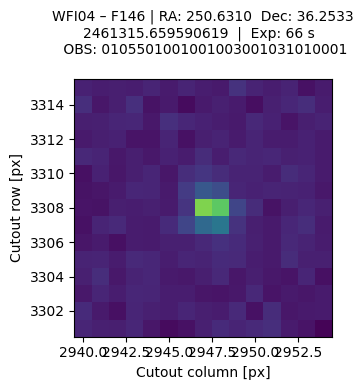

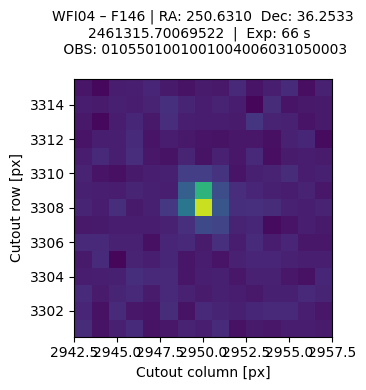

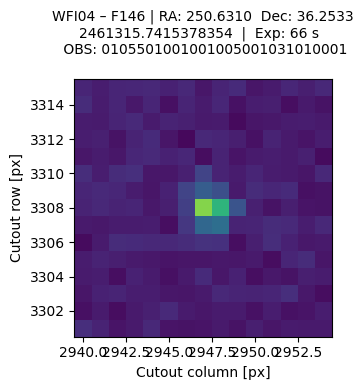

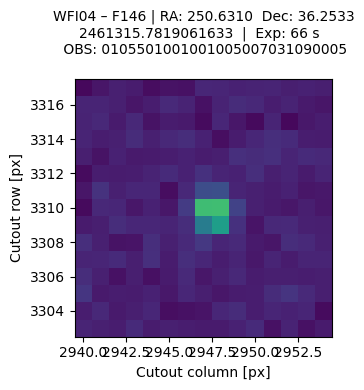

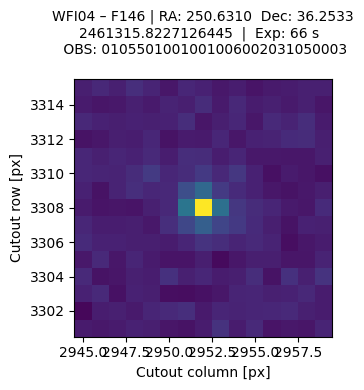

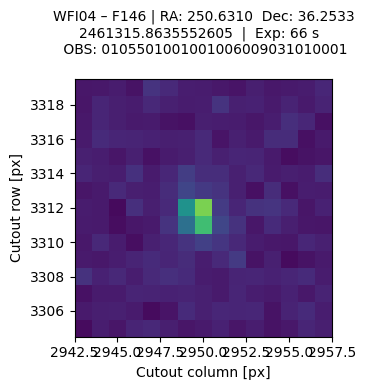

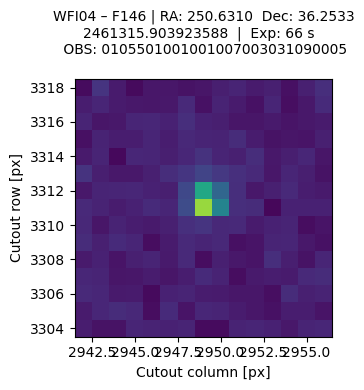

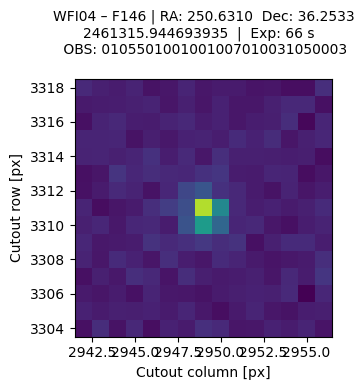

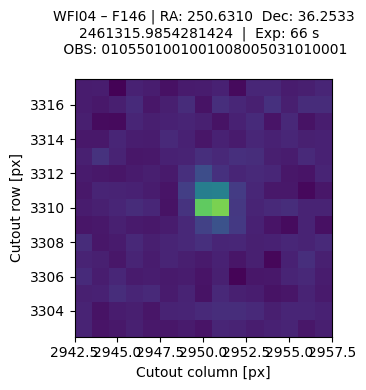

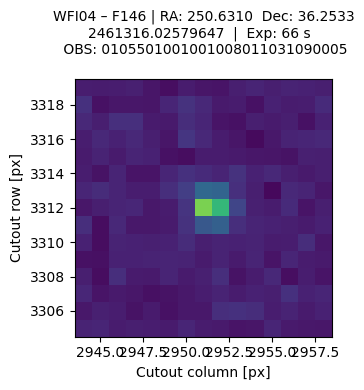

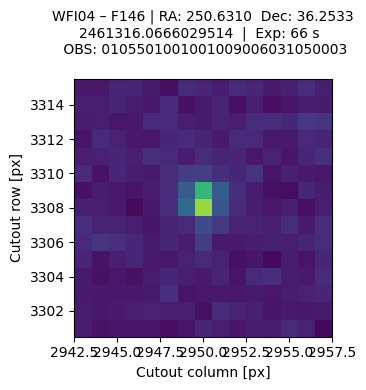

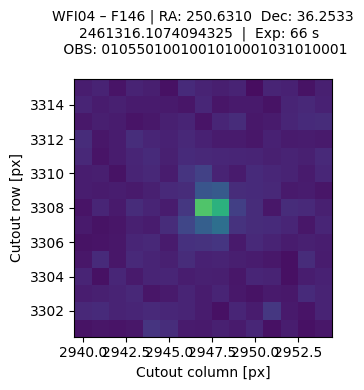

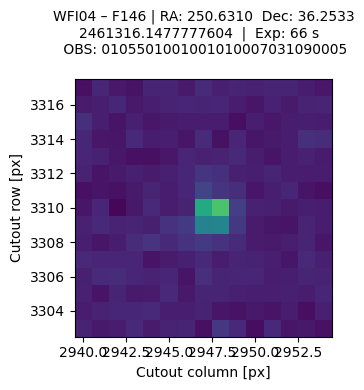

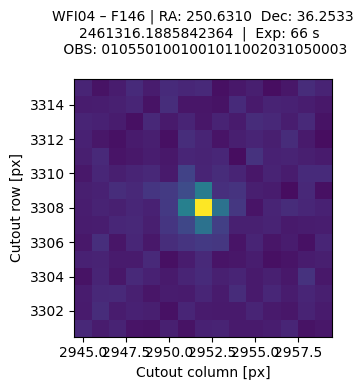

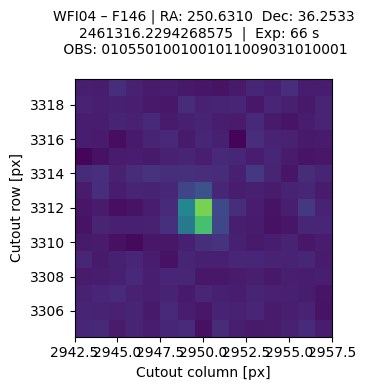

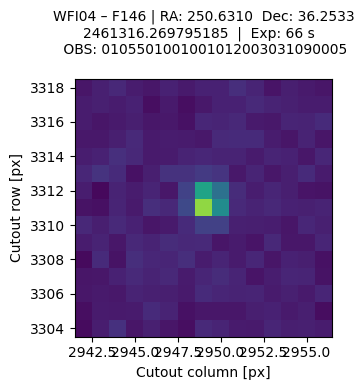

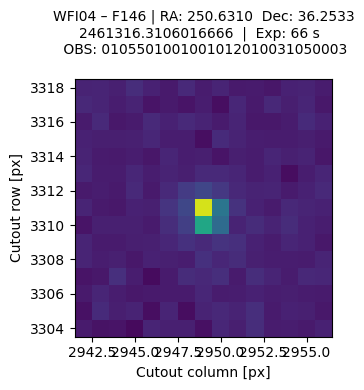

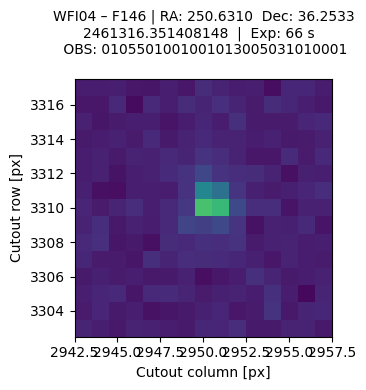

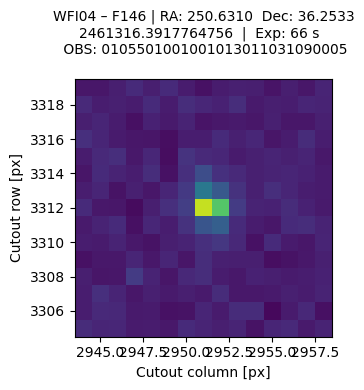

In [31]:
tar = 0
ext = 0

ny, nx = cube[tar].shape[-2], cube[tar].shape[-1]
norm = simple_norm(cube[tar][ext].ravel(), stretch="linear", percent=99.9)

for k in range(0, len(cube[tar][ext]), 40):
    if np.isnan(cube[tar][ext][k]).all():
        continue
    origin = meta[0].loc[k, "origin_original"]  # (col_min, row_min) from Cutout2D
    xmin, ymin = int(origin[0]), int(origin[1])

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_title(
        f'{meta[0].loc[k, "detector"]} – {meta[0].loc[k, "optical_element"]} | '
        f'RA: {meta[0].loc[k, "ra_target"]:.4f}  Dec: {meta[0].loc[k, "dec_target"]:.4f}\n'
        f'{meta[0].loc[k, "mid_time"]}  |  '
        f'Exp: {meta[0].loc[k, "exposure_time"]:.0f} s  \n '
        f'OBS: {meta[0].loc[k, "observation_id"]}\n',
        fontsize=10,
    )
    ax.pcolormesh(
        np.arange(xmin, xmin + nx),
        np.arange(ymin, ymin + ny),
        cube[tar][ext][k],
        norm=norm,
    )
    ax.set_aspect("equal", "box")
    ax.set_xlabel("Cutout column [px]")
    ax.set_ylabel("Cutout row [px]")
    plt.tight_layout()
    plt.show()


In [30]:
# 4. Save cutouts to a single ASDF
OUT_PATH = "/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts"
OUT_PATH = os.path.join(OUT_PATH, f"program_{pid}")
os.makedirs(OUT_PATH, exist_ok=True)

filenames = [os.path.join(OUT_PATH, f"cutouts_{pid}_{detector}_{filter}_{r:.6f}_{d:.6f}.asdf") for r, d in zip(ra, dec)]
print(f"Saving cutouts to {filenames}")

save_to_asdf(cube, meta, gwcss, filenames)

Saving cutouts to ['/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.630997_36.253313.asdf', '/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.633775_36.250535.asdf', '/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.625997_36.258313.asdf', '/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.644886_36.246369.asdf']


['/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.630997_36.253313.asdf',
 '/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.633775_36.250535.asdf',
 '/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.625997_36.258313.asdf',
 '/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts/program_1055/cutouts_1055_4_F146_250.644886_36.246369.asdf']

In [15]:
load_tree = asdf.open(filename)

In [16]:
load_tree.info()

root (AsdfObject)
├─asdf_library (Software)
│ ├─author (str): The ASDF Developers
│ ├─homepage (str): http://github.com/asdf-format/asdf
│ ├─name (str): asdf
│ └─version (str): 5.2.0
├─history (dict)
│ └─extensions (list)
│   ├─[0] (ExtensionMetadata) ...
│   ├─[1] (ExtensionMetadata) ...
│   ├─[2] (ExtensionMetadata) ...
│   ├─[3] (ExtensionMetadata) ...
│   ├─[4] (ExtensionMetadata) ...
│   └─2 not shown
└─roman (dict)
  ├─data (NDArrayType) ...
  ├─dq (NDArrayType) ...
  ├─dumo (NDArrayType) ...
  ├─err (NDArrayType) ...
  ├─meta (dict) ...
  ├─quality (NDArrayType) ...
  ├─time (list) ...
  └─wcs (list) ...
Some nodes not shown.


In [ ]:
meta

: 

: 